# Biomass downloader (ESA MAAP)
The logic lives in the `biomass` package (`src/biomass`). Install once with `pip install -e ".[geo,dev]"`, edit only the configuration cell and run top to bottom.

In [11]:
from pathlib import Path
from biomass import (BiomassClient, SearchQuery, Downloader, items_table, assets_table,
                     footprint_map, inspect_raster, plot_raster, raster_map)

# --- Configuration ---
QUERY = SearchQuery(
    collection="BiomassLevel1a",
    product_type="S1_SCS__1S",                 # None to skip filtering
    date_start="2026-01-01",
    date_end="2026-07-01",
    bbox=[-81.00, -20.00, -35.00, 10.00],      # [min_lon, min_lat, max_lon, max_lat]
    aoi_file=None,                             # e.g. "my_area.geojson" (overrides bbox)
    extra_filters={},                          # e.g. {"sat:orbit_state": "DESCENDING"}
    max_items=10,
)
ASSETS_TO_DOWNLOAD = ["quicklook_jpg", "enclosure_i_abs_tiff"]
OUTPUT_DIR = Path("../data")

client = BiomassClient()
client.auth.access_token(); print("Token OK")

Token OK


## Explore

In [12]:
client.collections()

,id,title,extent.temporal.interval
0,BiomassAux,Biomass Auxiliary,"[[2024-07-31T00:00:00.000Z, None]]"
1,BiomassAuxIOC,Biomass Auxiliary (IOC),"[[2024-07-31T00:00:00.000Z, None]]"
2,BiomassAuxRest,Biomass Auxiliary Restricted,"[[2024-07-31T00:00:00.000Z, None]]"
3,BiomassCalVal10,Biomass Cal/Val,"[[2025-04-29T00:00:00.000Z, None]]"
4,BiomassLevel0,Biomass Level 0,"[[2024-07-31T00:00:00.000Z, None]]"
5,BiomassLevel0IOC,Biomass Level 0 (IOC),"[[2024-07-31T00:00:00.000Z, None]]"
6,BiomassLevel1a,Biomass Level 1A,"[[2025-11-21T00:00:00.000Z, None]]"
7,BiomassLevel1aIOC,Biomass Level 1A (IOC),"[[2024-07-31T00:00:00.000Z, None]]"
8,BiomassLevel1b,Biomass Level 1B,"[[2024-07-31T00:00:00.000Z, None]]"
9,BiomassLevel1bIOC,Biomass Level 1B (IOC),"[[2024-07-31T00:00:00.000Z, None]]"


In [13]:
client.queryables(QUERY.collection)

,property,type,values,description
0,eofeos:repeat_cycle_id,string,"1, 10, 11, 2, 3, 4, 5, 6, 7, 8, 9, DR",Repeat cycle identifier. Each Major Cycle is s...
1,processing:facility,string,Biomass CPF,"The processing center (e.g. PDHS-E, PDHS-K, DP..."
2,eofeos:global_coverage_id,string,1,Global coverage identifier. Each Phase of the ...
3,product:type,string,"S1_SCS__1M, S1_SCS__1S, S2_SCS__1M, S2_SCS__1S...",A string identifying the entry type
4,platform,string,Biomass,The platform short name
5,eofeos:major_cycle_id,string,"1, 2, 3, 4, 5",Major cycle identifier. Each Global Coverage i...
6,datetime,string,,Temporal interval to search
7,instruments,string,P-SAR,"The instrument (e.g. MERIS, AATSR, ASAR, HRVIR..."
8,sat:orbit_state,string,"ASCENDING, DESCENDING",The acquisition orbit direction
9,productionStatus,string,ARCHIVED,The status of the entry


## Search

In [14]:
items = client.search(QUERY)
items_table(items)

10 products fetched | 3018 match in total


,idx,id,start,orbit,type,assets
0,0,BIO_S1_SCS__1S_20260513T232734_20260513T232752...,2026-05-13T23:27:34.965Z,descending,S1_SCS__1S,24
1,1,BIO_S1_SCS__1S_20260513T232715_20260513T232736...,2026-05-13T23:27:15.962Z,descending,S1_SCS__1S,24
2,2,BIO_S1_SCS__1S_20260513T232656_20260513T232717...,2026-05-13T23:26:56.958Z,descending,S1_SCS__1S,24
3,3,BIO_S1_SCS__1S_20260513T232637_20260513T232658...,2026-05-13T23:26:37.956Z,descending,S1_SCS__1S,24
4,4,BIO_S1_SCS__1S_20260513T232618_20260513T232639...,2026-05-13T23:26:18.955Z,descending,S1_SCS__1S,24
5,5,BIO_S1_SCS__1S_20260513T232559_20260513T232620...,2026-05-13T23:25:59.955Z,descending,S1_SCS__1S,24
6,6,BIO_S1_SCS__1S_20260513T232540_20260513T232601...,2026-05-13T23:25:40.956Z,descending,S1_SCS__1S,24
7,7,BIO_S1_SCS__1S_20260513T232521_20260513T232542...,2026-05-13T23:25:21.958Z,descending,S1_SCS__1S,24
8,8,BIO_S1_SCS__1S_20260513T232503_20260513T232523...,2026-05-13T23:25:03.341Z,descending,S1_SCS__1S,24
9,9,BIO_S1_SCS__1S_20260513T215253_20260513T215313...,2026-05-13T21:52:53.044Z,descending,S1_SCS__1S,24


In [15]:
footprint_map(items, QUERY)

## Download

In [16]:
assets_table(items[0])

,asset,media_type,href
0,enclosure_bio_common_types_xsd,text/xml,https://catalog.maap.eo.esa.int/data/biomass-p...
1,enclosure_i_abs_tiff,image/tiff,https://catalog.maap.eo.esa.int/data/biomass-p...
2,enclosure_overlay_support_xsd,text/xml,https://catalog.maap.eo.esa.int/data/biomass-p...
3,thumbnail,image/jpeg,https://catalog.maap.eo.esa.int/data/biomass-p...
4,enclosure_overlay_xsd,text/xml,https://catalog.maap.eo.esa.int/data/biomass-p...
5,product,application/zip,https://catalog.maap.eo.esa.int/data/zipper/bi...
6,metadata_iso_19139,application/vnd.iso.19139+xml,https://catalog.maap.eo.esa.int/catalogue/coll...
7,enclosure_annot_xml,text/xml,https://catalog.maap.eo.esa.int/data/biomass-p...
8,enclosure_i_phase_tiff,image/tiff,https://catalog.maap.eo.esa.int/data/biomass-p...
9,quicklook_jpg,image/jpg,https://catalog.maap.eo.esa.int/data/biomass-p...


In [17]:
files = Downloader(client.auth, OUTPUT_DIR).download(items, ASSETS_TO_DOWNLOAD)   # test first with items[:1]

  already exists, skipping: BIO_S1_SCS__1S_20260513T232734_20260513T232752_T_G01_M03_C07_T044_F161_02_DREMNJ.BI.JPG
  already exists, skipping: bio_s1_scs__1s_20260513t232734_20260513t232752_t_g01_m03_c07_t044_f161_i_abs.tiff
  already exists, skipping: BIO_S1_SCS__1S_20260513T232715_20260513T232736_T_G01_M03_C07_T044_F160_02_DREMOH.BI.JPG
  already exists, skipping: bio_s1_scs__1s_20260513t232715_20260513t232736_t_g01_m03_c07_t044_f160_i_abs.tiff
  already exists, skipping: BIO_S1_SCS__1S_20260513T232656_20260513T232717_T_G01_M03_C07_T044_F159_02_DREMM1.BI.JPG


bio_s1_scs__1s_20260513t232656_20260513t232717_t_g01_m03_c07_t044_f159_i_abs.tiff:  66%|######6   | 160M/242M …

KeyboardInterrupt: 

## Inspect

In [18]:
inspect_raster(next(OUTPUT_DIR.rglob("*.tiff")))

Size: 1334 x 20773 px | bands: 4 | dtype: float32
CRS: None | GCPs: 48
  band 1: (no description)  tags={'POLARIMETRIC_INTERP': 'HH'}
  band 2: (no description)  tags={'POLARIMETRIC_INTERP': 'HV'}
  band 3: (no description)  tags={'POLARIMETRIC_INTERP': 'VH'}
  band 4: (no description)  tags={'POLARIMETRIC_INTERP': 'VV'}
Metadata: {'TIFFTAG_IMAGEDESCRIPTION': 'BIOMASS L1', 'TIFFTAG_SOFTWARE': 'BPS-Biomass L1 Processor-4.4.3', 'TIFFTAG_DATETIME': '2026-05-14T16:44:21.827835', 'MATRIX_REPRESENTATION': 'SCATTERING', 'MAX_Z_ERROR': '0.0001', 'PolarisationsSequence': 'HH HV VH VV', 'Swath': 'S1', 'AREA_OR_POINT': 'Area'}


{'driver': 'GTiff',
 'dtype': 'float32',
 'nodata': -9999.0,
 'width': 1334,
 'height': 20773,
 'count': 4,
 'crs': None,
 'transform': Affine(1.0, 0.0, 0.0,
        0.0, 1.0, 0.0)}

## Visualize
`plot_raster` shows every polarisation of one file (dB, radar geometry). `raster_map` lays the downloaded files over a map: `band="rgb"` is a colour composite (R=HH, G=HV, B=VV), or pass `"HH"`, `"HV"`, `"VH"`, `"VV"` for a single polarisation.

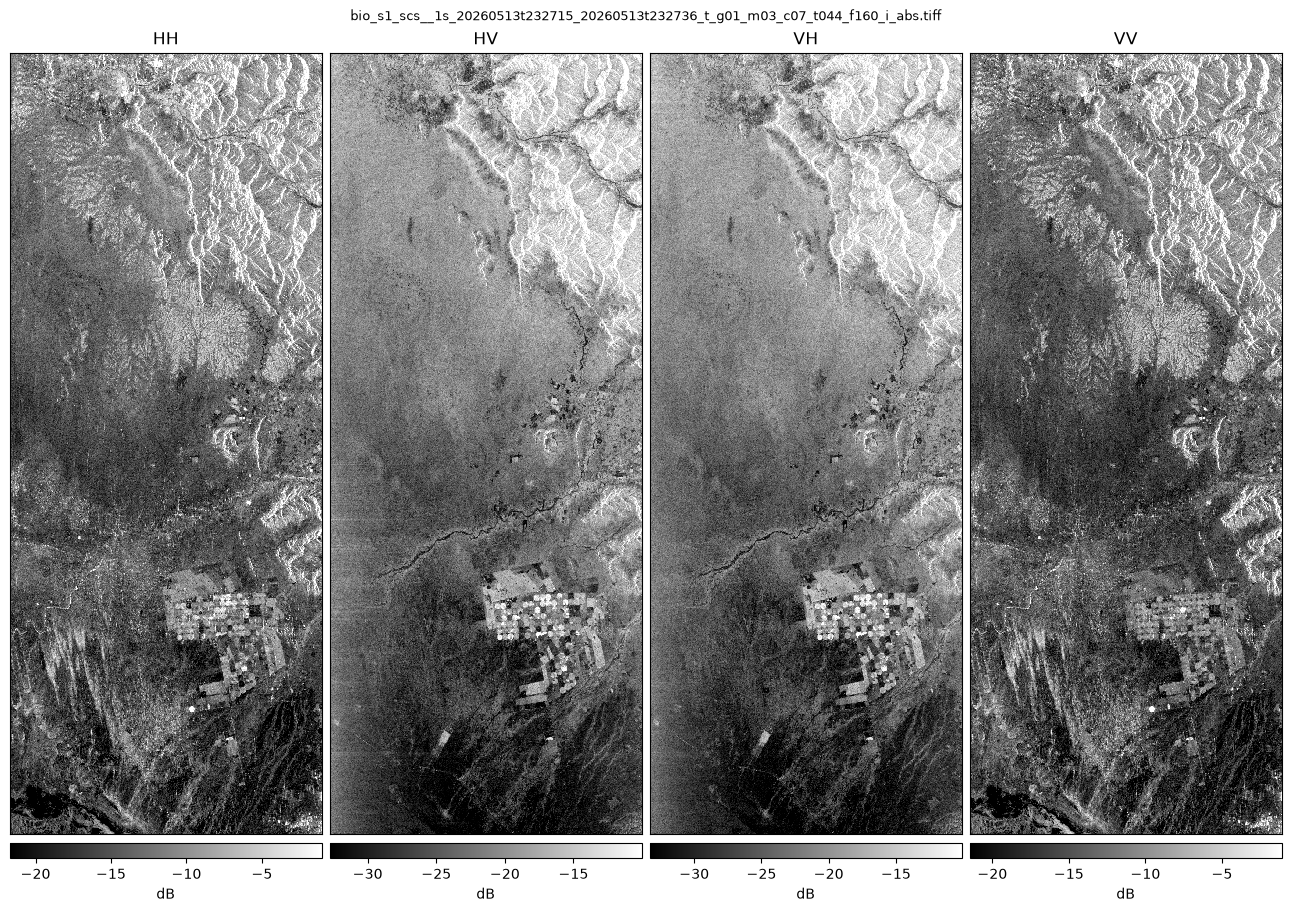

In [19]:
tiffs = sorted(OUTPUT_DIR.rglob("*.tiff"))
plot_raster(tiffs[0]);


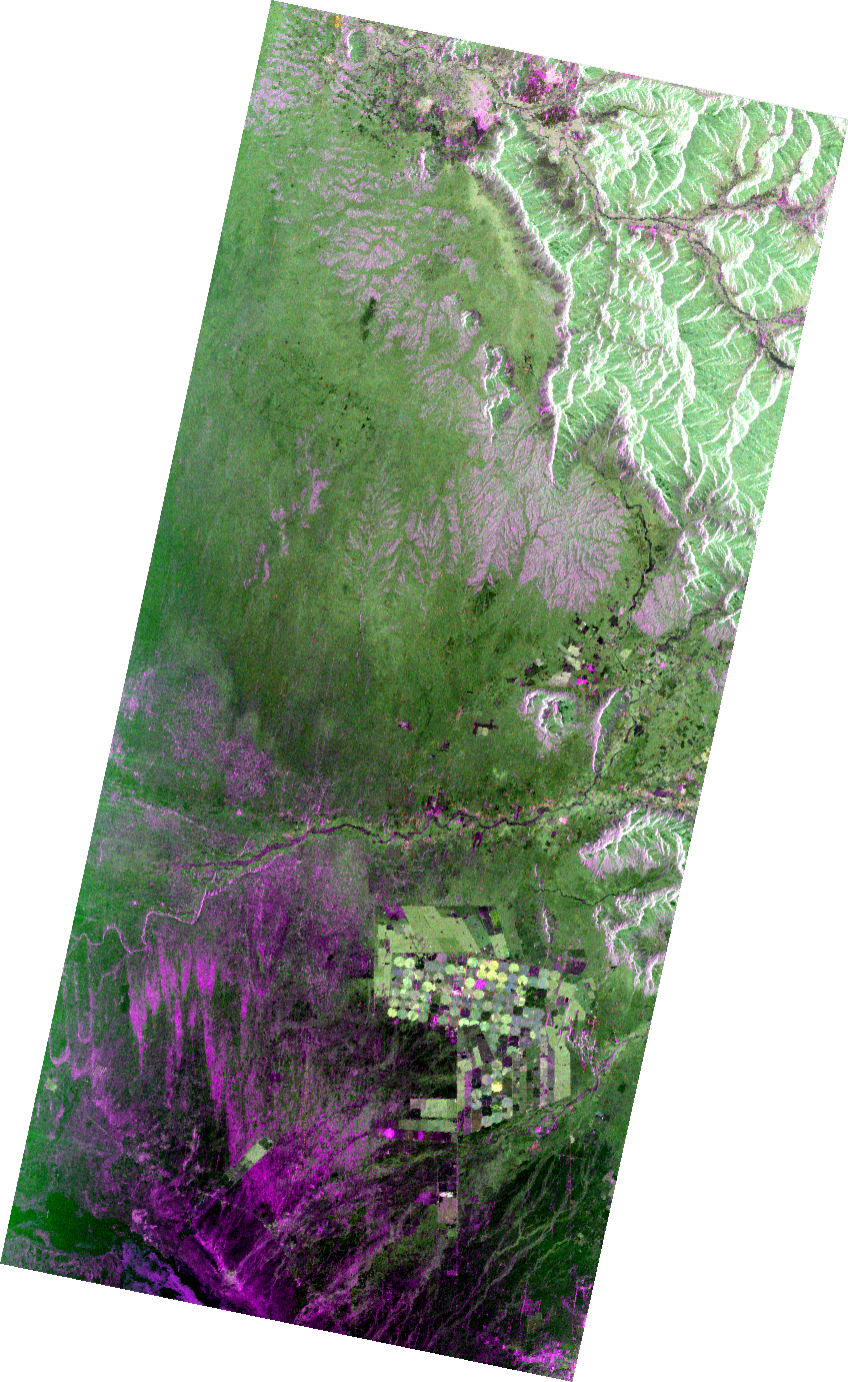
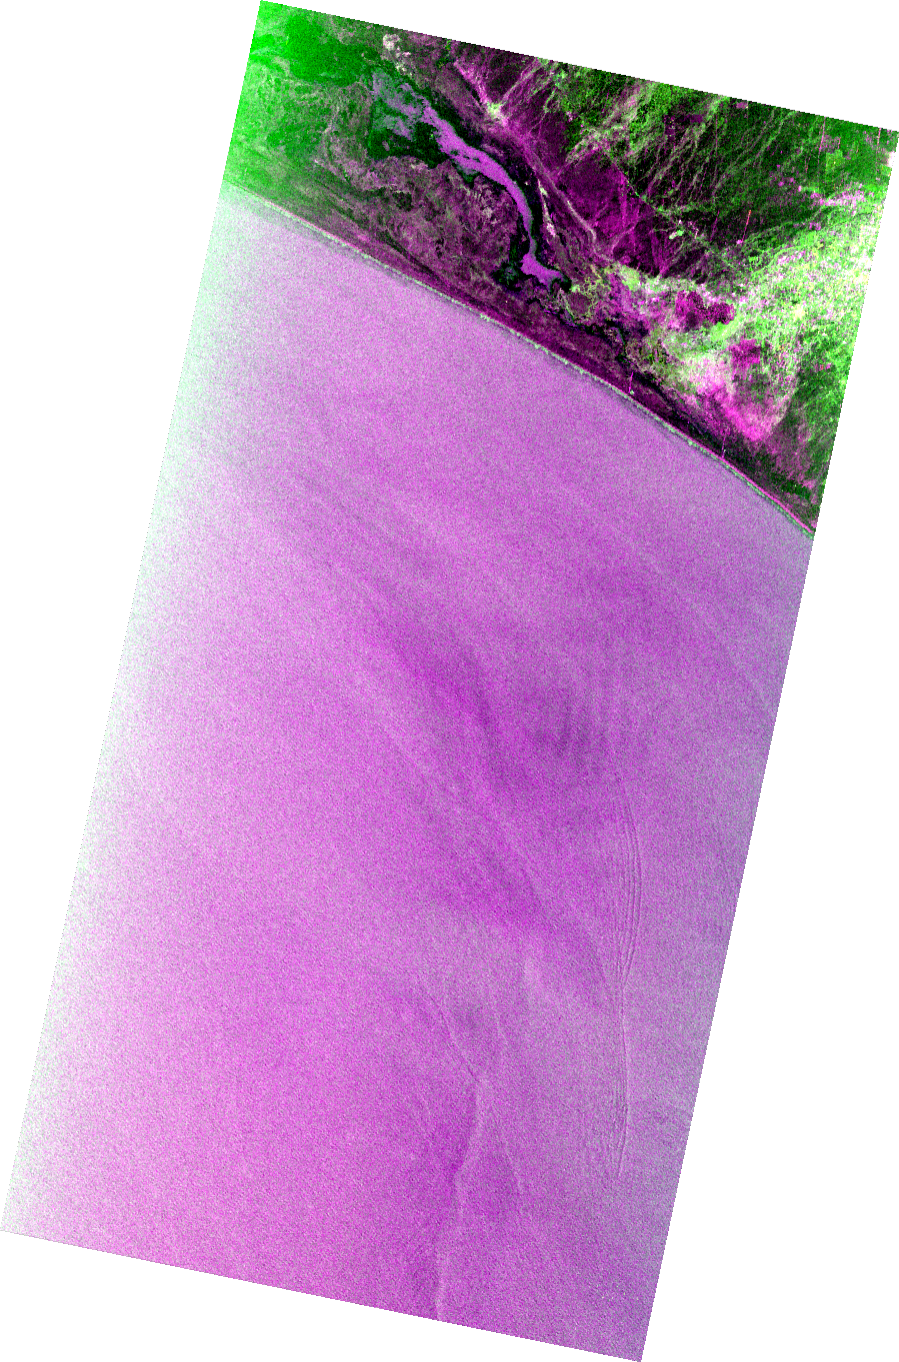

In [20]:
raster_map(tiffs)   # one layer per file; toggle them with the control in the top-right corner